<a href="https://colab.research.google.com/github/adeizaofficial/NUTDTS816-Oricha-NUTM-Time-Series-Analysis/blob/main/NUTDTS816_A2_Oricha_Adeiza_Philip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NUTDTS816 Assignment 2: Seasonal ARIMA Modelling
**Series:** Nigeria grid electricity generation, monthly average MW (Ember, "Total generation", Jan 2019 to Apr 2026, 88 months)

**Author:** Oricha Adeiza Philip    

**Course:** NUTDTS816 Time Series Analysis

 **Due:** 13 Nov 2026, 23:59 WAT

**Protocol.**

The last 12 months (May 2025 to Apr 2026) are held out and are not touched until Task 6.

**Training:** Jan 2019 to Apr 2025 (76 months).

| Task | Section |
|---|---|
| 1 | Look at the data, log decision |
| 2 | Stationarity and differencing |
| 3 | Shortlist of SARIMA candidates |
| 4 | Fit and compare |
| 5 | Residual diagnostics |
| 6 | Forecast and evaluate on the hold-out |
| 7 | ETS comparison |
| 8 | Summary for the manager (separate one-page PDF) |

In [72]:
# Setup (fresh Colab runtime): fetch the data from the course repository
!pip install -q statsmodels statsforecast
import os, urllib.request, warnings
REPO = "https://raw.githubusercontent.com/toadesina/NUTDTS816_Course_Repository/main"
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(f"{REPO}/src/tsdata.py", "tsdata.py")
for f in ["nigeria_grid.csv", "nigeria_grid.PROVENANCE.txt"]:
    urllib.request.urlretrieve(f"{REPO}/data/{f}", f"data/{f}")
print(open("data/nigeria_grid.PROVENANCE.txt").read())

nigeria_grid.csv: REAL. Nigeria monthly grid generation as average MW, Jan 2019 - Apr 2026 (88 months), from Ember
Monthly Electricity Data (CC-BY-4.0), "Total generation" rows, converted from TWh/month (TWh x 1e6 / hours in month).
Replaces the originally planned NERC/TCN/NSO source, which proved unavailable. Level 3,200-4,600 MW, consistent with the
Nigerian grid's operating range. Downloaded 24 Aug 2026. See raw/EXTRACTION_NOTES.md.



In [73]:
#Import the necessary libraries
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, itertools
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
import tsdata
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.grid": True, "grid.alpha": .3})

y = tsdata.nigeria_grid().asfreq("MS")
assert y.isna().sum() == 0 and len(y) == 88
H, S = 12, 12

# hold-out length, seasonal period
train, test = y.iloc[:-H], y.iloc[-H:]

# hold-out is split off here and not used again until Task 6
print(f"All: {y.index[0]:%b %Y} to {y.index[-1]:%b %Y} (n={len(y)})")
print(f"Train: {train.index[0]:%b %Y} to {train.index[-1]:%b %Y} (n={len(train)})")
print(f"Hold-out: {test.index[0]:%b %Y} to {test.index[-1]:%b %Y} (n={len(test)})")

All: Jan 2019 to Apr 2026 (n=88)
Train: Jan 2019 to Apr 2025 (n=76)
Hold-out: May 2025 to Apr 2026 (n=12)


## Task 1. Look at the training data

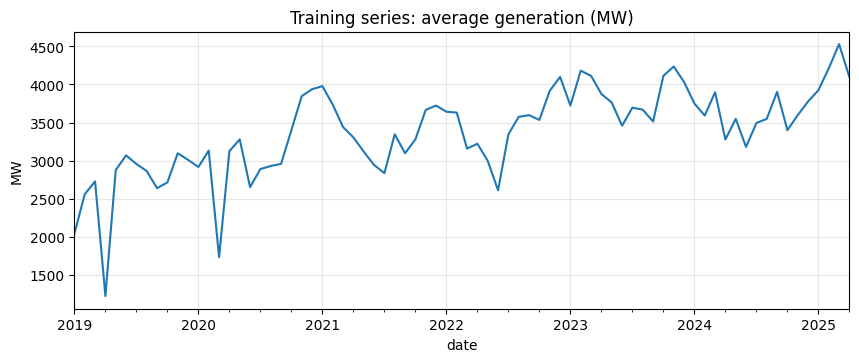

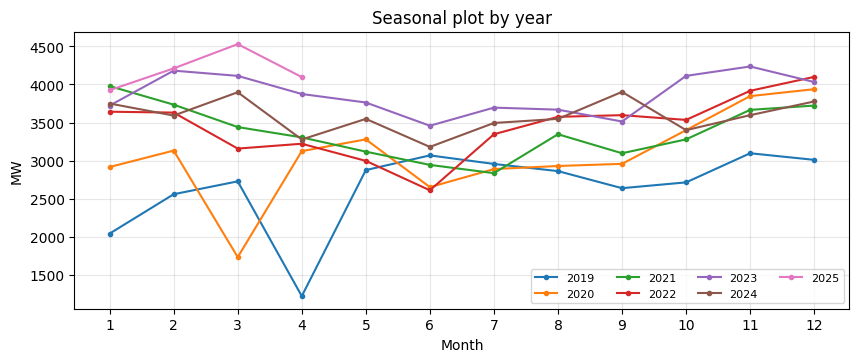

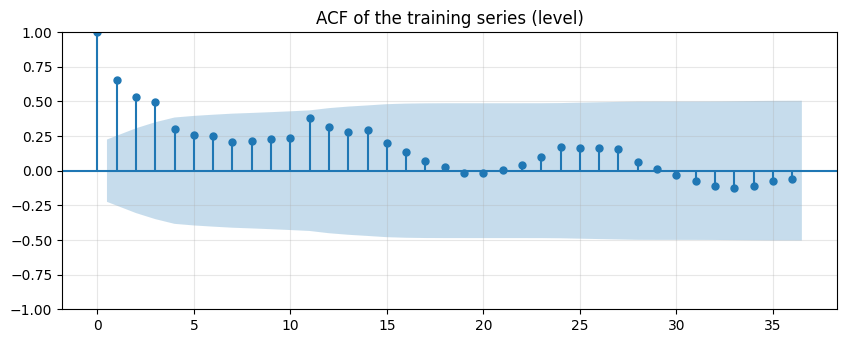

In [74]:
fig, ax = plt.subplots(); train.plot(ax=ax, color="C0"); ax.set_title("Training series: average generation (MW)"); ax.set_ylabel("MW"); plt.show()

# Seasonal plot: one line per year across the calendar months
sp = train.to_frame("mw"); sp["year"], sp["month"] = sp.index.year, sp.index.month
fig, ax = plt.subplots()
for yr, g in sp.groupby("year"): ax.plot(g["month"], g["mw"], marker="o", ms=3, label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_title("Seasonal plot by year"); ax.set_xlabel("Month"); ax.set_ylabel("MW"); ax.legend(ncol=4, fontsize=8); plt.show()

fig, ax = plt.subplots(); plot_acf(train, lags=36, ax=ax); ax.set_title("ACF of the training series (level)"); plt.show()

In [75]:
# Evidence for the log decision to ascertain if the spread grows with the level?

yr = train.groupby(train.index.year).agg(mean="mean", sd="std", lo="min", hi="max", n="count").round(0)
yr["cv_%"] = (100 * yr["sd"] / yr["mean"]).round(1)
display(yr)
full = yr[yr.n == 12]               # complete years only

print("Correlation of yearly mean and yearly sd (complete years):", round(full["mean"].corr(full["sd"]), 2))
print("Largest month-on-month drops (%):"); display((train.pct_change() * 100).nsmallest(4).round(1))
print("Seasonal index (mean of month / year mean, complete years):")
si = (train / train.groupby(train.index.year).transform("mean"))[train.index.year.isin(full.index)]
display(si.groupby(si.index.month).mean().round(3).to_frame("index").T)

,mean,sd,lo,hi,n,cv_%
date,,,,,,
2019,2648.0,533.0,1222.0,3097.0,12,20.1
2020,3067.0,569.0,1734.0,3938.0,12,18.6
2021,3373.0,349.0,2836.0,3978.0,12,10.3
2022,3444.0,406.0,2611.0,4100.0,12,11.8
2023,3865.0,265.0,3458.0,4236.0,12,6.9
2024,3581.0,227.0,3181.0,3903.0,12,6.3
2025,4191.0,255.0,3925.0,4530.0,4,6.1


Correlation of yearly mean and yearly sd (complete years): -0.86
Largest month-on-month drops (%):


,generation_mw
date,
2019-04-01,-55.2
2020-03-01,-44.6
2020-06-01,-19.1
2024-04-01,-15.9


Seasonal index (mean of month / year mean, complete years):


date,1,2,3,4,5,6,7,8,9,10,11,12
index,0.995,1.039,0.948,0.886,0.986,0.906,0.967,1.001,0.987,1.024,1.125,1.136


**Commentary (Task 1).**

**Trend:**

 The level rises over the sample: the average was about 2,650 MW in 2019 and about 3,865 MW in 2023, with a dip in 2024 (about 3,580 MW) and a recovery to about 4,190 MW in the first four months of 2025. The ACF of the level decays slowly (0.65 at lag 1, 0.53 at lag 2, 0.50 at lag 3), which is the signature of a trending, non-stationary series.

**Seasonality.**

Seasonality is present but moderate and irregular in a series with only six full years. Averaged over complete years, November and December run about 12 to 14% above the annual mean, while April and June are the weakest months (about 10% below). The ACF shows a secondary peak at lag 11 to 12 (0.38 and 0.32).
*Breaks.* Two collapses stand out: April 2019 (1,222 MW, a fall of 55% on March, followed by a rebound of 135% in May) and March 2020 (a fall of 45%, rebound of 80% in April). Further falls occur in June 2020 (19%), April 2024 (16%) and October 2024 (13%). These are operational collapses of the grid, not seasonal movements; they inflate the 2019 and 2020 variation and will produce occasional large residuals that no seasonal model can anticipate.


**Log decision:No log transformation.**

A log helps when seasonal swings and noise grow in proportion to the level. Here the yearly standard deviation does not grow with the yearly mean; it falls (about 530 to 570 MW in 2019 to 2020, against 230 to 270 MW in 2023 to 2025 while the level was higher), and the correlation between yearly mean and yearly standard deviation is -0.86 (complete years). The dominant variance comes from downward collapses, which a log would magnify rather than stabilise. The model therefore works in MW, and forecasts need no back-transformation.

## Task 2. Stationarity and differencing

In [76]:
def tests(x, name):
    x = pd.Series(x).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")           # silences a library FutureWarning and KPSS's lookup-table warning
        a = adfuller(x, autolag="AIC", regression="c")
        k = kpss(x, regression="c", nlags="auto")
    return {"series": name, "n": len(x), "ADF stat": round(a[0], 2), "ADF p": round(a[1], 4),
            "KPSS stat": round(k[0], 3), "KPSS p": round(k[1], 4)}
cand = {"level (d=0, D=0)":        train,
        "d=1":                     train.diff(),
        "D=1 (lag-12 difference)": train.diff(S),
        "d=1, D=1":                train.diff().diff(S)}
tab = pd.DataFrame([tests(v, k) for k, v in cand.items()]).set_index("series")
tab["ADF verdict (5%)"]  = np.where(tab["ADF p"]  < .05, "reject unit root", "cannot reject unit root")
tab["KPSS verdict (5%)"] = np.where(tab["KPSS p"] < .05, "reject stationarity", "cannot reject stationarity")
display(tab)

print("ADF  H0: the series has a unit root (non-stationary).   Reject => evidence of stationarity.")
print("KPSS H0: the series is level-stationary.                Reject => evidence of non-stationarity.")
print("KPSS p-values are interpolated from a table and are bounded to [0.01, 0.10].")

,n,ADF stat,ADF p,KPSS stat,KPSS p,ADF verdict (5%),KPSS verdict (5%)
series,,,,,,,
"level (d=0, D=0)",76,-4.02,0.0013,1.156,0.0100,reject unit root,reject stationarity
d=1,75,-5.81,0.0000,0.273,0.1000,reject unit root,cannot reject stationarity
D=1 (lag-12 difference),64,-4.19,0.0007,0.260,0.1000,reject unit root,cannot reject stationarity
"d=1, D=1",63,-2.26,0.1847,0.500,0.0417,cannot reject unit root,reject stationarity


ADF  H0: the series has a unit root (non-stationary).   Reject => evidence of stationarity.
KPSS H0: the series is level-stationary.                Reject => evidence of non-stationarity.
KPSS p-values are interpolated from a table and are bounded to [0.01, 0.10].


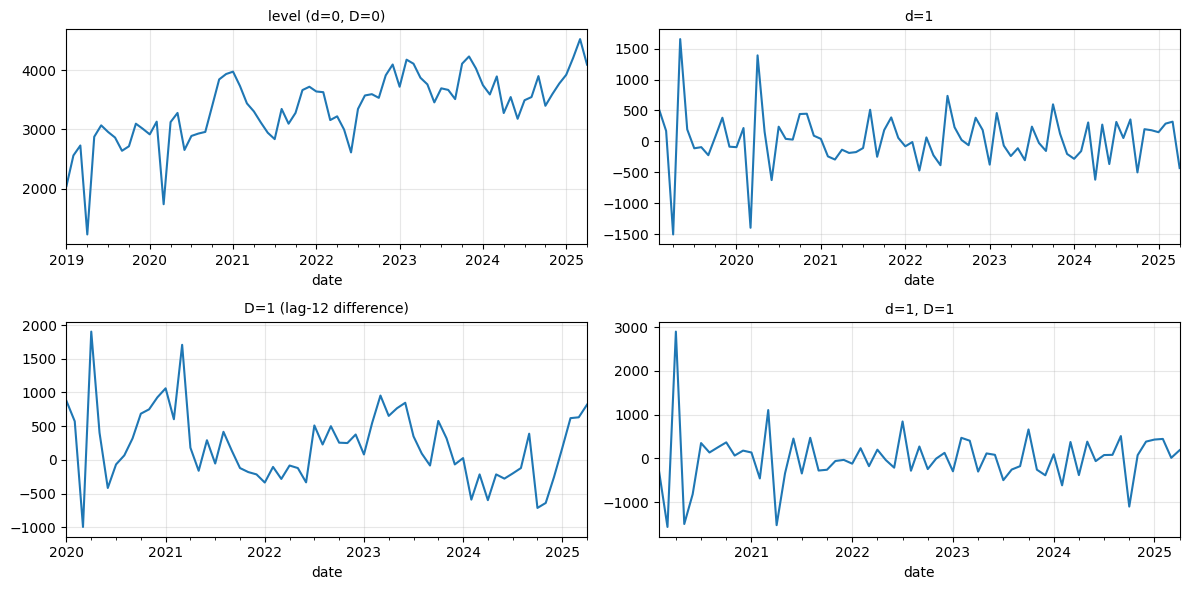

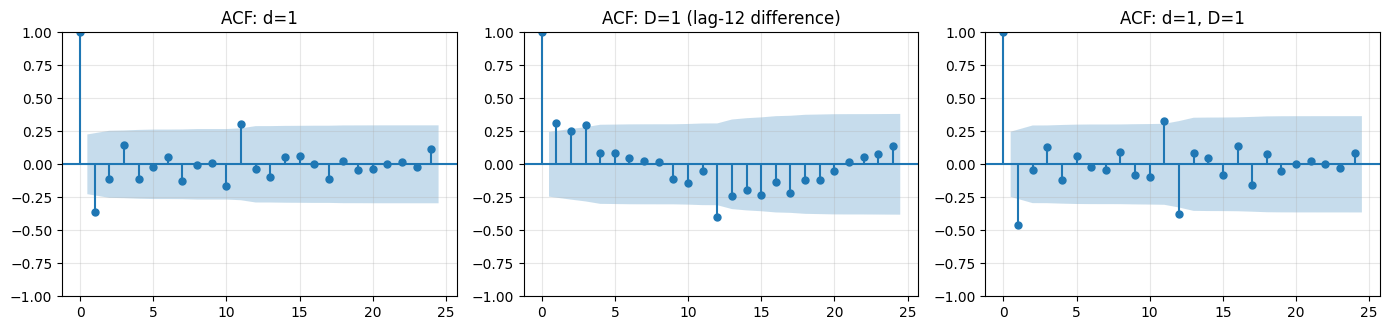

In [77]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (k, v) in zip(axes.ravel(), cand.items()):
    v.dropna().plot(ax=ax); ax.set_title(k, fontsize=10)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, k in zip(axes, ["d=1", "D=1 (lag-12 difference)", "d=1, D=1"]):
    plot_acf(cand[k].dropna(), lags=24, ax=ax, title="ACF: " + k)
plt.tight_layout(); plt.show()

**Commentary (Task 2).**

 The decision uses the tests, the plots and the ACFs together, because the tests have low power on 76 points and the 2019 and 2020 collapses distort them. ADF has H0 = unit root (reject means stationary); KPSS has H0 = level-stationary (reject means non-stationary).

- **Level.**

ADF rejects a unit root (stat -4.02, p = 0.0013) but KPSS rejects stationarity (stat 1.156, p ≤ 0.01). The tests disagree. The slowly decaying ACF (0.65, 0.53, 0.50) and the visible upward trend side with KPSS: the level is not stationary, and differencing is needed.
- **First difference (d=1).**  ADF p < 0.0001 and KPSS p ≥ 0.10 (stat 0.273). Both agree the series is stationary.

- **Seasonal difference only (D=1).** ADF p = 0.0007 and KPSS p ≥ 0.10 (stat 0.260). Both also agree it is stationary.

- **Both (d=1, D=1).** ADF p = 0.185 (cannot reject a unit root) and KPSS p = 0.042 (rejects stationarity). Both tests now say non-stationary, although the series was already stationary after a single difference. This is the signature of **over-differencing**: the second difference adds a non-invertible moving-average component and removes the information the tests rely on. The lag-1 ACF of -0.46, close to the -0.5 limit, points the same way.

- **Choice: d = 1, D = 0.**
One regular difference is sufficient, with both tests in agreement, and it keeps 75 observations. A seasonal difference does not improve the evidence, and adding it makes both tests fail. D = 1 alone also passes both tests, but the lag-12 ACF of -0.40 after that difference signals that the seasonal pattern is being over-removed, and it would need a drift term to carry the upward trend. Seasonality is moderate and irregular in this series (peaks in November and December, about 12 to 14% above the annual mean), so it is handled by seasonal AR/MA terms rather than by seasonal differencing. The two admissible options (d=1, D=0 and d=0, D=1) are not distinguishable by ADF/KPSS alone; I choose the one with the fewest differences. This is a judgement, and I note it as a limitation.

## Task 3. Shortlist of SARIMA(p,d,q)(P,D,Q)12 candidates

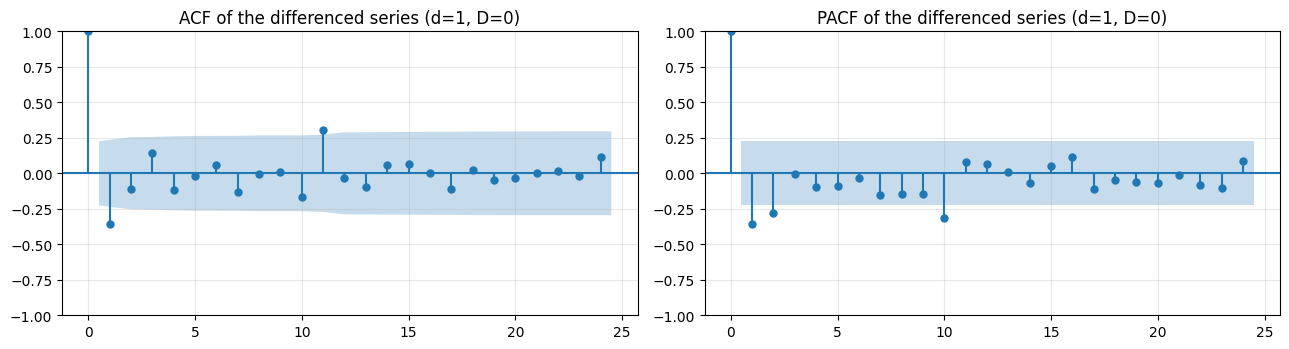

Approximate 95% band: +/- 0.23


In [78]:
d, D = 1, 0                      # Task 2 decision: one regular difference, no seasonal difference
z = train.diff(S).diff() if (d, D) == (1, 1) else train.diff(S) if (d, D) == (0, 1) else train.diff() if (d, D) == (1, 0) else train
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(z.dropna(), lags=24, ax=axes[0], title=f"ACF of the differenced series (d={d}, D={D})")
plot_pacf(z.dropna(), lags=24, ax=axes[1], method="ywm", title=f"PACF of the differenced series (d={d}, D={D})")
plt.tight_layout(); plt.show()
print("Approximate 95% band: +/-", round(1.96 / np.sqrt(z.dropna().shape[0]), 2))

**Reading the ACF and PACF (d=1, D=0; 75 observations, 95% band about ±0.23).** ACF: lag 1 = -0.36, lag 11 = +0.30, everything else inside the band. PACF: lag 1 = -0.36, lag 2 = -0.28, lag 10 = -0.31, then inside the band. The short-lag structure looks like an MA(1) or an AR(2). There is a seasonal footprint around lags 10 to 12, but it is weaker than the short-lag structure, so seasonal terms are tested rather than assumed.

| Model | Pattern behind it |
|---|---|
| **M0: (0,1,1)(0,0,0)12** | Non-seasonal benchmark. ACF cuts off after lag 1 (MA(1)). Tests whether seasonal terms are needed at all. |
| **M1: (0,1,1)(1,0,0)12** | MA(1) for the lag-1 spike plus a seasonal AR(1) for the annual pattern seen near lags 10 to 12. |
| **M2: (0,1,1)(0,0,1)12** | Same MA(1), with the annual pattern modelled as a seasonal MA(1) instead. |
| **M3: (2,1,0)(1,0,0)12** | PACF has two significant spikes (lags 1 and 2) before it dies out, an AR(2) reading of the short lags, with a seasonal AR(1). |
| **M4: (1,1,1)(1,0,0)12** | The ACF and PACF both tail off, which suggests a mixed ARMA at the short lags. |

In [79]:
CANDIDATES = {
    "M0 (0,1,1)(0,0,0)12": ((0, d, 1), (0, D, 0, S)),
    "M1 (0,1,1)(1,0,0)12": ((0, d, 1), (1, D, 0, S)),
    "M2 (0,1,1)(0,0,1)12": ((0, d, 1), (0, D, 1, S)),
    "M3 (2,1,0)(1,0,0)12": ((2, d, 0), (1, D, 0, S)),
    "M4 (1,1,1)(1,0,0)12": ((1, d, 1), (1, D, 0, S)),
}

## Task 4. Fit and compare

In [80]:
def fit_sarima(order, sorder, series=train):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        res = SARIMAX(series, order=order, seasonal_order=sorder).fit(disp=False, maxiter=500)
    warn = sorted({str(x.category.__name__) + ": " + str(x.message)[:70] for x in w})
    if not res.mle_retvals.get("converged", True): warn.append("optimizer did not converge")
    return res, warn

def compare(cands):
    rows, fits = [], {}
    for name, (o, so) in cands.items():
        assert (o[1], so[1]) == (d, D), "AICc is only comparable across models with the same d and D"
        res, warn = fit_sarima(o, so)
        burn = o[1] + so[1] * S                      # residuals lost to differencing are not informative
        e = res.resid.iloc[burn:]
        k = o[0] + o[2] + so[0] + so[2]              # ARMA parameters, for the Ljung-Box degrees of freedom
        lb = acorr_ljungbox(e, lags=[24], model_df=k)["lb_pvalue"].iloc[0]
        rows.append({"model": name, "k (AR+MA terms)": k, "AIC": res.aic, "AICc": res.aicc, "BIC": res.bic,
                     "LB p (lag 24)": lb, "warnings": "; ".join(warn) if warn else "none"})
        fits[name] = res
    t = pd.DataFrame(rows).set_index("model").sort_values("AICc")
    t["dAICc"] = t["AICc"] - t["AICc"].min()
    return t, fits

def prefer(t):
    tied = t[t["dAICc"] <= 2]                         # within about 2 AICc of the best
    clean = tied[tied["warnings"] == "none"]
    pool = clean if len(clean) else tied
    return pool.sort_values(["k (AR+MA terms)", "AICc"]).index[0]

tab4, fits = compare(CANDIDATES)
display(tab4.round({"AIC": 1, "AICc": 1, "BIC": 1, "LB p (lag 24)": 3, "dAICc": 2}))
best = prefer(tab4); print("Preferred (within 2 AICc of the minimum, then fewest terms, then clean fit):", best)
display(fits[best].summary().tables[1])

,k (AR+MA terms),AIC,AICc,BIC,LB p (lag 24),warnings,dAICc
model,,,,,,,
"M0 (0,1,1)(0,0,0)12",1,1118.4,1118.6,1123.1,0.307,none,0.00
"M1 (0,1,1)(1,0,0)12",2,1119.7,1120.0,1126.6,0.448,none,1.40
"M2 (0,1,1)(0,0,1)12",2,1119.9,1120.2,1126.8,0.394,none,1.62
"M4 (1,1,1)(1,0,0)12",3,1120.9,1121.5,1130.2,0.409,none,2.91
"M3 (2,1,0)(1,0,0)12",3,1121.3,1121.9,1130.6,0.501,none,3.31


Preferred (within 2 AICc of the minimum, then fewest terms, then clean fit): M0 (0,1,1)(0,0,0)12


,coef,std err,z,P>|z|,[0.025,0.975]
ma.L1,-0.5004,0.098,-5.095,0.000,-0.693,-0.308
sigma2,1.638e+05,2.43e+04,6.738,0.000,1.16e+05,2.11e+05


**Commentary (Task 4).**

AICc is comparable here because all five candidates share d = 1, D = 0 and the same untransformed series. M0 has the lowest AICc (1118.6). M1 (+1.40) and M2 (+1.62) are within about 2 AICc of it and are therefore statistically tied with M0; M4 (+2.91) and M3 (+3.31) are clearly worse. No model produced an estimation warning, and every Ljung-Box p-value at lag 24 lies between 0.31 and 0.50, so none of the candidates leaves detectable autocorrelation.

**Preferred model: M0, SARIMA(0,1,1)(0,0,0)12.**

 Under the tie rule (models within about 2 AICc are equivalent, so take the simpler) M0 wins, because it has one ARMA parameter against two for M1 and M2. Adding a seasonal AR or seasonal MA term at lag 12 does not improve the fit enough to pay for itself, which means the data give no support for explicit seasonal terms: seasonality in this series is moderate and irregular (Task 1), and the single regular difference with an MA(1) captures the structure that matters. The MA(1) coefficient is -0.500 (standard error 0.098, p < 0.001), clearly significant and well inside the invertibility boundary of -1, and the innovation variance is 1.64 × 10^5 (a residual standard deviation of about 405 MW). Note that M0 is formally a SARIMA with (P, D, Q) = (0, 0, 0), that is, an ARIMA(0,1,1); M1 and M2 remain the seasonal alternatives, and with only six full annual cycles in the training data seasonal parameters are weakly identified.

## Task 5. Residual diagnostics of the preferred model

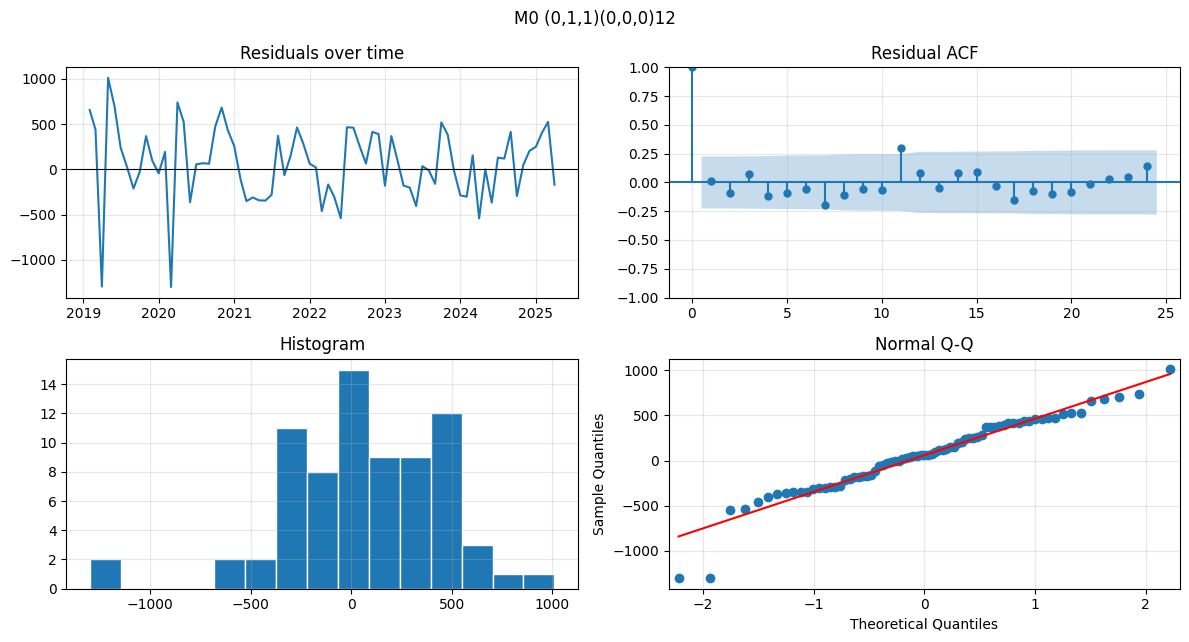

    lb_stat  lb_pvalue
12   16.780      0.115
24   25.865      0.307
Largest |residuals| (MW):
date
2020-03-01    1302.0
2019-04-01    1296.0
2019-05-01    1012.0
2020-04-01     740.0


In [81]:
def diagnose(res, name, k):
    burn = d + D * S
    e = res.resid.iloc[burn:]
    fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
    ax[0, 0].plot(e); ax[0, 0].axhline(0, color="k", lw=.8); ax[0, 0].set_title("Residuals over time")
    plot_acf(e, lags=24, ax=ax[0, 1], title="Residual ACF")
    ax[1, 0].hist(e, bins=15, edgecolor="w"); ax[1, 0].set_title("Histogram")
    sm.qqplot(e, line="s", ax=ax[1, 1]); ax[1, 1].set_title("Normal Q-Q")
    fig.suptitle(name); plt.tight_layout(); plt.show()
    lb = acorr_ljungbox(e, lags=[12, 24], model_df=k)
    print(lb.round(3))
    print("Largest |residuals| (MW):"); print(e.abs().nlargest(4).round(0).to_string())
diagnose(fits[best], best, tab4.loc[best, "k (AR+MA terms)"])

**Commentary (Task 5).**

The residuals of M0 behave like white noise.
- **Residual time plot.** The residuals fluctuate around zero with no trend and no visible change in level. The large negative values (about -1,300 MW) are confined to 2019 and 2020; from 2021 onwards the residuals stay within roughly ±500 MW.
- **Residual ACF.** All bars lie inside the 95% band except lag 11 (about +0.30). One exceedance in 24 lags is what chance alone would produce at the 5% level, and the same lag-11 bump appeared in the differenced series in Task 3; the seasonal candidates M1 and M2 target lag 12 and did not improve AICc, so it does not justify extra terms.
- **Ljung-Box test.** H0: the residuals are independent. The statistic is 16.78 at lag 12 (p = 0.115) and 25.87 at lag 24 (p = 0.307); H0 is not rejected at either lag, with the degrees of freedom adjusted for the one estimated MA parameter.
- **Histogram and Q-Q plot.** The histogram is roughly bell-shaped and centred near zero, and the Q-Q points follow the reference line through the middle of the distribution. Two points in the lower tail lie far below the line. They are March 2020 (-1,302 MW) and April 2019 (-1,296 MW), the grid collapses identified in Task 1; the next largest residuals, May 2019 (+1,012 MW) and April 2020 (+740 MW), are the rebounds that followed them. The residuals are therefore approximately normal apart from a few outlying shock months.
- **Judgement.** There is no remaining serial correlation, so the model has captured the systematic structure. The collapses are unforecastable shocks rather than a modelling omission; they make the residual distribution heavier-tailed than normal, which should make the prediction intervals slightly less reliable at the extremes but does not bias the mean forecast.

In [82]:
# One allowed return to Task 3. Runs only if the preferred model fails the lag-24 Ljung-Box test (p < 0.05).
needs_round2 = tab4.loc[best, "LB p (lag 24)"] < 0.05
print("Round 2 needed:", needs_round2)
if needs_round2:
    extra = {"M5 (1,1,2)(1,0,0)12": ((1, d, 2), (1, D, 0, S)),
             "M6 (2,1,1)(1,0,0)12": ((2, d, 1), (1, D, 0, S)),
             "M7 (0,1,3)(1,0,0)12": ((0, d, 3), (1, D, 0, S))}   # <- replace by what the residual ACF suggests
    tab4b, fits_b = compare({**CANDIDATES, **extra}); fits.update(fits_b)
    display(tab4b.round({"AIC": 1, "AICc": 1, "BIC": 1, "LB p (lag 24)": 3, "dAICc": 2}))
    best = prefer(tab4b); print("Preferred after round 2:", best)
    diagnose(fits[best], best, tab4b.loc[best, "k (AR+MA terms)"])
    tab4 = tab4b

Round 2 needed: False


**Round 2 note.** Not needed: the preferred model's residuals passed the Ljung-Box test at lag 24 (p = 0.307), so the one permitted return to Task 3 was not used and the shortlist was not changed after seeing the residuals.

## Task 6. Forecast the 12-month hold-out and evaluate

In [83]:
def mase_scale(tr, m=S): return np.mean(np.abs(tr.values[m:] - tr.values[:-m]))
SCALE = mase_scale(train)                      # in-sample seasonal-naive MAE: the MASE denominator

def metrics(actual, fc):
    e = actual.values - np.asarray(fc)
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)), "MASE": np.mean(np.abs(e)) / SCALE}

def coverage(actual, lo, hi): return float(np.mean((actual.values >= np.asarray(lo)) & (actual.values <= np.asarray(hi))))

# SARIMA forecast with 80% and 95% intervals
fc = fits[best].get_forecast(H)
mean = fc.predicted_mean; ci80 = fc.conf_int(alpha=.20); ci95 = fc.conf_int(alpha=.05)
sar = pd.DataFrame({"fc": mean, "lo80": ci80.iloc[:, 0], "hi80": ci80.iloc[:, 1], "lo95": ci95.iloc[:, 0], "hi95": ci95.iloc[:, 1]})
assert (sar.index == test.index).all()

# Seasonal naive: repeat the last 12 training months; intervals from the in-sample seasonal-difference residuals
from scipy.stats import norm
sn = pd.Series(train.values[-S:], index=test.index)
sig = np.std(train.values[S:] - train.values[:-S], ddof=1)
hh = np.arange(1, H + 1); sd_h = sig * np.sqrt(np.floor((hh - 1) / S) + 1)
snv = pd.DataFrame({"fc": sn, "lo80": sn - norm.ppf(.9) * sd_h, "hi80": sn + norm.ppf(.9) * sd_h,
                    "lo95": sn - norm.ppf(.975) * sd_h, "hi95": sn + norm.ppf(.975) * sd_h})

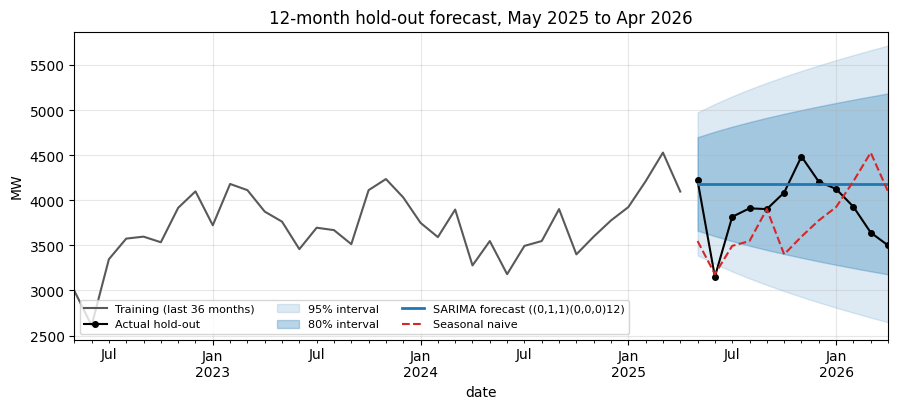

In [84]:
fig, ax = plt.subplots(figsize=(10.5, 4))
train.iloc[-36:].plot(ax=ax, color="0.35", label="Training (last 36 months)")
test.plot(ax=ax, color="k", marker="o", ms=4, label="Actual hold-out")
ax.fill_between(sar.index, sar.lo95, sar.hi95, color="C0", alpha=.15, label="95% interval")
ax.fill_between(sar.index, sar.lo80, sar.hi80, color="C0", alpha=.30, label="80% interval")
sar["fc"].plot(ax=ax, color="C0", lw=2, label=f"SARIMA forecast ({best.split(' ', 1)[1]})")
sn.plot(ax=ax, color="C3", ls="--", label="Seasonal naive")
ax.set_ylabel("MW"); ax.set_title("12-month hold-out forecast, May 2025 to Apr 2026"); ax.legend(ncol=3, fontsize=8, loc="lower left")
fig.savefig("a2_forecast.png", dpi=200, bbox_inches="tight"); plt.show()

## Task 7. ETS comparison (statsforecast AutoETS)

In [85]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS
dfx = pd.DataFrame({"unique_id": "nigeria", "ds": train.index, "y": train.values})
sf = StatsForecast(models=[AutoETS(season_length=S)], freq="MS")
ets = sf.forecast(df=dfx, h=H, level=[80, 95]).set_index("ds")
assert (ets.index == test.index).all()
try:
    print("AutoETS selected form:", AutoETS(season_length=S).fit(train.values).model_["method"])
except Exception as ex:
    print("(selected form not exposed in this statsforecast version)", type(ex).__name__)
etsv = pd.DataFrame({"fc": ets["AutoETS"], "lo80": ets["AutoETS-lo-80"], "hi80": ets["AutoETS-hi-80"],
                     "lo95": ets["AutoETS-lo-95"], "hi95": ets["AutoETS-hi-95"]})

AutoETS selected form: ETS(A,N,N)


In [86]:
rows = []
for name, f in [(f"SARIMA {best.split(' ', 1)[1]}", sar), ("Seasonal naive", snv), ("AutoETS", etsv)]:
    m = metrics(test, f["fc"])
    rows.append({"Model": name, **{k: round(v, 3 if k == "MASE" else 1) for k, v in m.items()},
                 "80% coverage": coverage(test, f.lo80, f.hi80), "95% coverage": coverage(test, f.lo95, f.hi95)})
evaluation = pd.DataFrame(rows).set_index("Model")
display(evaluation)
print(f"MASE scale (in-sample seasonal-naive MAE, training) = {SCALE:.1f} MW. Coverage is the share of the 12 hold-out months inside the interval (each month = 8.3 percentage points).")
display(pd.DataFrame({"actual": test, "SARIMA": sar.fc, "snaive": sn, "AutoETS": etsv.fc}).round(0))

,MAE,RMSE,MASE,80% coverage,95% coverage
Model,,,,,
"SARIMA (0,1,1)(0,0,0)12",328.3,435.2,0.742,0.916667,0.916667
Seasonal naive,446.5,532.1,1.009,0.833333,1.000000
AutoETS,325.0,431.1,0.734,0.916667,0.916667


MASE scale (in-sample seasonal-naive MAE, training) = 442.5 MW. Coverage is the share of the 12 hold-out months inside the interval (each month = 8.3 percentage points).


,actual,SARIMA,snaive,AutoETS
2025-05-01,4220.0,4182.0,3548.0,4176.0
2025-06-01,3153.0,4182.0,3181.0,4176.0
2025-07-01,3817.0,4182.0,3495.0,4176.0
2025-08-01,3911.0,4182.0,3548.0,4176.0
2025-09-01,3903.0,4182.0,3903.0,4176.0
2025-10-01,4086.0,4182.0,3400.0,4176.0
2025-11-01,4486.0,4182.0,3597.0,4176.0
2025-12-01,4207.0,4182.0,3777.0,4176.0
2026-01-01,4126.0,4182.0,3925.0,4176.0
2026-02-01,3929.0,4182.0,4211.0,4176.0


**Commentary (Tasks 6 and 7).**

**Accuracy against the benchmark.** On the 12 hold-out months (May 2025 to April 2026) the SARIMA(0,1,1) has MAE 328.3 MW, RMSE 435.2 MW and MASE 0.742, against 446.5 MW, 532.1 MW and 1.009 for the seasonal naive. MAE is therefore about 26% lower and RMSE about 18% lower than the benchmark, and MASE below 1 means the model beats the in-sample seasonal-naive error. The SARIMA has the smaller absolute error in 8 of the 12 months. The forecast is a flat 4,182 MW because the model has no seasonal terms; it over-forecast on average by about 267 MW (actual minus forecast), mainly because generation fell after January 2026.

**Largest errors.** June 2025 is the largest miss: actual 3,153 MW against a forecast of 4,182 MW (error -1,029 MW), a collapse of the same kind as those in 2019 and 2020 that no model could anticipate. Next are April 2026 (-682 MW), March 2026 (-540 MW) and July 2025 (-365 MW). November 2025 is the largest under-forecast (+304 MW), the usual seasonal peak that a flat forecast cannot show.

**Interval coverage.** The 80% interval contained 11 of 12 actual values (91.7%) and the 95% interval also 11 of 12 (91.7%); the one miss in both is June 2025. The 80% interval is somewhat generous and the 95% interval slightly below its nominal level, but with 12 observations one month is 8.3 percentage points, so neither departure is statistically distinguishable from correct calibration. The seasonal-naive intervals covered 83.3% (80%) and 100% (95%).

**ETS comparison.** AutoETS selected ETS(A,N,N) (simple exponential smoothing with no trend and no seasonality, a model equivalent to ARIMA(0,1,1)) and obtained MAE 325.0, RMSE 431.1 and MASE 0.734 against 328.3, 435.2 and 0.742 for the SARIMA; the two models give almost identical forecasts (4,176 MW against 4,182 MW) and the 3 MW difference in MAE is far too small to separate them on 12 test points, so I treat them as equally accurate and prefer the SARIMA only for its explicit diagnostics.

## Task 8. Hand-off to the one-page manager summary

In [87]:
import json
out = {"preferred": best, "evaluation": evaluation.reset_index().to_dict("records"),
       "forecast_next_12_months_note": "see table above"}
# Forecast the NEXT 12 months (May 2026 to Apr 2027) by refitting the preferred model on all 88 months
order, sorder = CANDIDATES.get(best, None) or {**CANDIDATES, **(extra if 'extra' in globals() else {})}[best]
full_res = SARIMAX(y, order=order, seasonal_order=sorder).fit(disp=False, maxiter=500)
nf = full_res.get_forecast(12); nci = nf.conf_int(alpha=.2)
nxt = pd.DataFrame({"fc": nf.predicted_mean, "lo80": nci.iloc[:, 0], "hi80": nci.iloc[:, 1]}).round(0)
display(nxt); print("Next-12-month mean forecast (MW):", round(nxt.fc.mean()), " 80% range of monthly values:", int(nxt.lo80.min()), "to", int(nxt.hi80.max()))
out["next12"] = nxt.reset_index().astype({"index": str}).to_dict("records")
json.dump(out, open("a2_results.json", "w"), indent=1, default=float)
print(json.dumps(out["evaluation"], indent=1, default=float))

,fc,lo80,hi80
2026-05-01,3673.0,3157.0,4189.0
2026-06-01,3673.0,3096.0,4250.0
2026-07-01,3673.0,3041.0,4305.0
2026-08-01,3673.0,2991.0,4356.0
2026-09-01,3673.0,2944.0,4403.0
2026-10-01,3673.0,2899.0,4447.0
2026-11-01,3673.0,2857.0,4489.0
2026-12-01,3673.0,2818.0,4529.0
2027-01-01,3673.0,2780.0,4567.0
2027-02-01,3673.0,2743.0,4603.0


Next-12-month mean forecast (MW): 3673  80% range of monthly values: 2674 to 4672
[
 {
  "Model": "SARIMA (0,1,1)(0,0,0)12",
  "MAE": 328.3,
  "RMSE": 435.2,
  "MASE": 0.742,
  "80% coverage": 0.9166666666666666,
  "95% coverage": 0.9166666666666666
 },
 {
  "Model": "Seasonal naive",
  "MAE": 446.5,
  "RMSE": 532.1,
  "MASE": 1.009,
  "80% coverage": 0.8333333333333334,
  "95% coverage": 1.0
 },
 {
  "Model": "AutoETS",
  "MAE": 325.0,
  "RMSE": 431.1,
  "MASE": 0.734,
  "80% coverage": 0.9166666666666666,
  "95% coverage": 0.9166666666666666
 }
]


## AI-use statement
Claude (Anthropic) was used to debug errors and structure the notebook. All code, estimates, figures and conclusions were run and checked by me, and I am accountable for every line.